#### 08B · Validación del emulador con periodo (PVAR → XGBoost Hs y Tm02 → ruido conjunto TVAR bivariado)
Misma validación de Hs que el 08 (secciones 1–6 y 5B), sobre las simulaciones del 07B, más una sección 7 para el periodo: régimen medio de Tm02, Tm02 condicionado a Hs, dependencia en la cola (χ), Tm02 en los picos de temporal y peralte. Referencia: el hindcast del 05B (f histórica + ruido conjunto).

In [1]:
import glob, os, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genextreme
from scipy.signal import find_peaks

In [2]:
#### Configuración
point = "p102"
GEN = "h1bb24"
carpeta = f"outputs/emulador_hstm/{GEN}"
fichero_val = f"outputs/emulador_hstm/validacion_{GEN}.pkl"

os.makedirs("figuras", exist_ok=True)

olas_obs = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True).loc["1985":"2025", ["VHM0", "VTM02"]]
obs = olas_obs["VHM0"].dropna()
tm_obs = olas_obs["VTM02"].reindex(obs.index)
N_ANOS = obs.index.year.nunique()                   # longitud de cada bloque simulado
ficheros = sorted(glob.glob(f"{carpeta}/sim_*.parquet"))

U90, U99 = obs.quantile(0.90), obs.quantile(0.99)   # umbrales fijos (observados) para duraciones y temporales
U95 = obs.quantile(0.95)                            # umbral de los temporales de la sección 5B
Q_FINO = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), 1 - np.logspace(-2, -4.5, 26)]))
Q_TABLA = [0.5, 0.9, 0.99, 0.999]
LAGS = np.arange(0, 241)                            # hasta 10 días
T_RET = [2, 10, 50, 100]
print(f"obs: {N_ANOS} años | {len(ficheros)} simulaciones | U90 = {U90:.2f} m, U99 = {U99:.2f} m")

#### Periodo: clases de Hs (20, por cuantiles de la Hs observada) para Tm02 | Hs, y umbrales de χ(u)
BORDES_H = obs.quantile(np.linspace(0, 1, 21)).values[1:-1]
CENTROS_H = obs.groupby(np.digitize(obs, BORDES_H)).median().values
US = np.array([0.80, 0.90, 0.95, 0.98, 0.99, 0.995])
G = 9.81

obs: 41 años | 100 simulaciones | U90 = 1.91 m, U99 = 3.73 m


In [3]:
#### Estilo presentación
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})

def banda(ax, x, arr, color=AZUL, label="sim. p5–p95", mediana=True):
    """Banda p5–p95 (y mediana) entre bloques simulados; arr con forma (bloque, x)."""
    p5, p50, p95 = np.nanpercentile(arr, [5, 50, 95], axis=0)
    ax.fill_between(x, p5, p95, color=color, alpha=0.25, lw=0, label=label)
    if mediana:
        ax.plot(x, p50, color=color, lw=1.5, label="sim. mediana")

#### Estadísticos de un bloque (se aplica igual a la observación y a cada bloque simulado)

In [4]:
#### Funciones de temporales (5B): se definen aquí porque estadisticos() las usa
SEP_H = 48                                   # dos excedencias separadas más de 48 h son temporales distintos

def eventos(s, u, sep=SEP_H):
    """Temporales por excedencia de u, agrupados por rachas: duración, pico, energía, subida y bajada."""
    v = s.asfreq("h").values
    exc = np.flatnonzero(v > u)
    if len(exc) < 2:
        return pd.DataFrame(columns=["inicio", "dur", "pico", "energia", "subida", "bajada"])
    grupo = np.r_[0, np.cumsum(np.diff(exc) > sep)]
    filas = []
    for g in np.unique(grupo):
        i = exc[grupo == g]
        tramo = v[i[0]:i[-1] + 1]
        k = np.nanargmax(tramo)
        filas.append({"inicio": i[0], "dur": len(i), "pico": tramo[k],
                      "energia": np.nansum(v[i] ** 2), "subida": k, "bajada": len(tramo) - 1 - k})
    return pd.DataFrame(filas)

def theta_intervalos(s, u):
    """Índice extremal: estimador de intervalos de Ferro y Segers (2003)."""
    T = np.diff(np.flatnonzero(s.asfreq("h").values > u)).astype(float)
    if len(T) < 2:
        return np.nan
    N = len(T) + 1
    if T.max() <= 2:
        return min(1.0, 2 * T.sum() ** 2 / ((N - 1) * (T ** 2).sum()))
    return min(1.0, 2 * (T - 1).sum() ** 2 / ((N - 1) * ((T - 1) * (T - 2)).sum()))

In [5]:
def acf(s, lags):
    """Autocorrelación de la serie horaria (con huecos como NaN)."""
    x = s.asfreq("h").values.astype("float64")
    x = x - np.nanmean(x)
    v = np.nanmean(x * x)
    return np.array([1.0 if l == 0 else np.nanmean(x[:-l] * x[l:]) / v for l in lags])

def duraciones(s, u):
    """Duración (h) de cada racha continua por encima de u."""
    sobre = np.concatenate([[0], (s.asfreq("h").values > u).astype(int), [0]])
    d = np.diff(sobre)
    return np.flatnonzero(d == -1) - np.flatnonzero(d == 1)

def gev_niveles(am):
    c, loc, sc = genextreme.fit(am)
    return {"xi": -c, **{f"Hs{T}": genextreme.isf(1 / T, c, loc, sc) for T in T_RET}}

def estadisticos(s, tm=None):
    """s: Hs horaria de un bloque de N_ANOS años completos; tm: Tm02 horaria del mismo bloque (opcional)."""
    anual = s.groupby(s.index.year)
    am = anual.max().values
    picos, _ = find_peaks(s.values, height=U99, distance=72)
    media_anual = anual.mean().values
    out = {
        "q": s.quantile(Q_FINO).values,
        "media": s.mean(), "std": s.std(),
        "acf": acf(s, LAGS),
        "dur90": duraciones(s, U90),
        "mes_media": s.groupby(s.index.month).mean().values,
        "mes_q90": s.groupby(s.index.month).quantile(0.90).values,
        "mes_q99": s.groupby(s.index.month).quantile(0.99).values,
        "mes_max": s.groupby([s.index.year, s.index.month]).max().groupby(level=1).mean().values,
        "hora_media": s.groupby(s.index.hour).mean().values,
        "anual_media": media_anual, "anual_q95": anual.quantile(0.95).values,
        "std_anual_media": media_anual.std(), "std_anual_q95": anual.quantile(0.95).std(),
        "ac1_anual_media": np.corrcoef(media_anual[:-1], media_anual[1:])[0, 1],
        "am": np.sort(am),
        "temporales_10a": len(picos) * 10 / s.index.year.nunique(),
        "picos": s.values[picos],
        **gev_niveles(am),
        **{f"theta_q{q}": theta_intervalos(s, uq) for q, uq in [(95, U95), (99, U99)]},
        "ev95": eventos(s, U95), "ev99": eventos(s, U99),
        "n_ev95_ano": eventos(s, U95).assign(ano=lambda d: s.index[d["inicio"].astype(int)].year)
                        .groupby("ano").size().reindex(np.unique(s.index.year), fill_value=0).values,
    }
    if tm is not None:
        t = tm.reindex(s.index)
        ok = t.notna().values
        h_, t_ = s[ok], t[ok]
        U, V = h_.rank() / (len(h_) + 1), t_.rank() / (len(t_) + 1)
        cls = np.digitize(h_.values, BORDES_H)
        peralte = h_ / (G * t_ ** 2 / (2 * np.pi))
        chi = np.array([((U > u) & (V > u)).sum() / (U > u).sum() for u in US])
        out.update({
            "tm_q": t_.quantile(Q_FINO).values, "tm_media": t_.mean(), "tm_q99": t_.quantile(0.99),
            "tm_mes_media": t_.groupby(t_.index.month).mean().values,
            "tm_acf": acf(t, LAGS), "tm_acf24": acf(t, [0, 24])[1],
            "corr_hs_tm": h_.corr(t_), "spearman_hs_tm": U.corr(V),
            "tm_cond": t_.groupby(cls).quantile([0.1, 0.5, 0.9]).unstack().reindex(range(len(BORDES_H) + 1)).values,   # (clase, q10/q50/q90)
            "chi": chi, "chi95": chi[US == 0.95][0], "chi99": chi[US == 0.99][0],
            "tm_picos_med": np.nanmedian(t.values[picos]),
            "peralte_q99": peralte.quantile(0.99), "peralte_max": peralte.max(),
        })
    return out

In [6]:
#### Observación y bloques simulados (se guarda para no recalcular)
est_obs = estadisticos(obs, tm_obs)

if os.path.exists(fichero_val):
    est_sim = pickle.load(open(fichero_val, "rb"))["sim"]
    print(f"cargados {len(est_sim)} bloques de {fichero_val}")
else:
    est_sim = []
    for i, fic in enumerate(ficheros):
        t = time.time()
        df = pd.read_parquet(fic, columns=["VHM0", "VTM02"]).astype("float64")
        hs, tm = df["VHM0"], df["VTM02"]
        anos = np.unique(hs.index.year)
        anos = anos[[hs.loc[str(a)].size >= 8700 for a in anos]]           # solo años completos
        for b in range(len(anos) // N_ANOS):
            bloque = anos[b * N_ANOS:(b + 1) * N_ANOS]
            sel = hs.index.year.isin(bloque)
            est_sim.append(estadisticos(hs[sel], tm[sel]))
        print(f"sim {i:03d}: {len(anos) // N_ANOS} bloques ({time.time() - t:.0f} s)", flush=True)
    pickle.dump({"obs": est_obs, "sim": est_sim}, open(fichero_val, "wb"))

pila = lambda k: np.array([e[k] for e in est_sim])                     # (bloque, ...)
print(f"{len(est_sim)} bloques de {N_ANOS} años")

sim 000: 2 bloques (2 s)
sim 001: 2 bloques (2 s)
sim 002: 2 bloques (2 s)
sim 003: 2 bloques (2 s)
sim 004: 2 bloques (2 s)
sim 005: 2 bloques (2 s)
sim 006: 2 bloques (2 s)
sim 007: 2 bloques (2 s)
sim 008: 2 bloques (2 s)
sim 009: 2 bloques (2 s)
sim 010: 2 bloques (2 s)
sim 011: 2 bloques (2 s)
sim 012: 2 bloques (2 s)
sim 013: 2 bloques (2 s)
sim 014: 2 bloques (2 s)
sim 015: 2 bloques (2 s)
sim 016: 2 bloques (2 s)
sim 017: 2 bloques (2 s)
sim 018: 2 bloques (2 s)
sim 019: 2 bloques (2 s)
sim 020: 2 bloques (2 s)
sim 021: 2 bloques (2 s)
sim 022: 2 bloques (2 s)
sim 023: 2 bloques (2 s)
sim 024: 2 bloques (2 s)
sim 025: 2 bloques (2 s)
sim 026: 2 bloques (2 s)
sim 027: 2 bloques (2 s)
sim 028: 2 bloques (2 s)
sim 029: 2 bloques (2 s)
sim 030: 2 bloques (2 s)
sim 031: 2 bloques (2 s)
sim 032: 2 bloques (2 s)
sim 033: 2 bloques (2 s)
sim 034: 2 bloques (2 s)
sim 035: 2 bloques (2 s)
sim 036: 2 bloques (2 s)
sim 037: 2 bloques (2 s)
sim 038: 2 bloques (2 s)
sim 039: 2 bloques (2 s)


In [7]:
#### Rango percentil de la observación dentro de los bloques simulados (≈ 50 ideal; < 5 o > 95 = fuera de banda)
def rango(k, v_obs=None):
    v_obs = est_obs[k] if v_obs is None else v_obs
    return 100 * np.mean(pila(k) < v_obs)

def fila(nombre, k):
    s = pila(k); p5, p50, p95 = np.percentile(s, [5, 50, 95])
    o = est_obs[k]
    return {"métrica": nombre, "obs": o, "sim p50": p50, "sim p5": p5, "sim p95": p95,
            "sesgo %": 100 * (p50 - o) / o if o else np.nan, "en banda": p5 <= o <= p95}

#### 1. Régimen medio: distribución de la Hs horaria

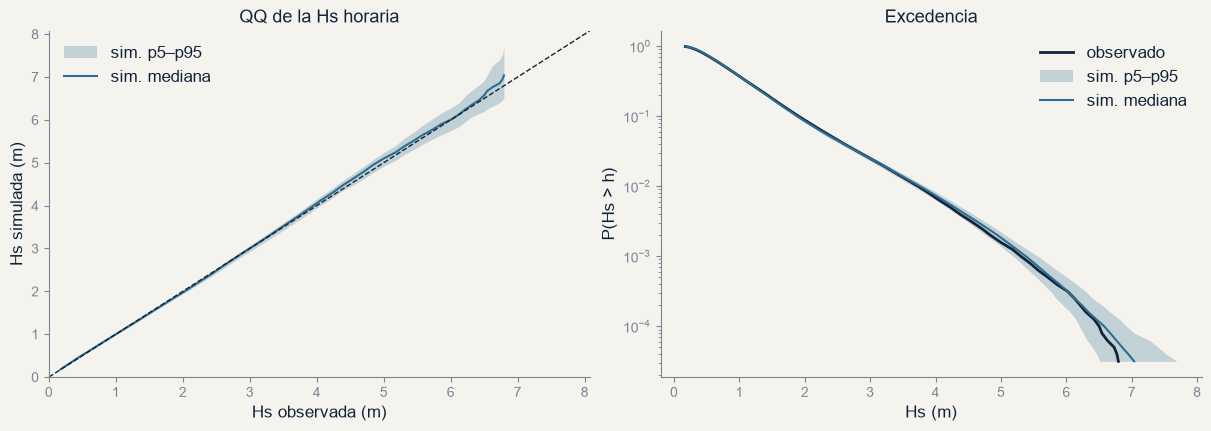

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
media,0.998,1.000,0.984,1.015,0.252,True
std,0.731,0.727,0.709,0.741,-0.593,True
q50,0.796,0.801,0.788,0.815,0.623,True
q90,1.905,1.883,1.854,1.914,-1.141,True
q99,3.731,3.762,3.657,3.846,0.828,True
q99.9,5.304,5.380,5.186,5.567,1.435,True


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

#### QQ: cuantiles simulados frente a observados
qs = pila("q")
p5, p50, p95 = np.percentile(qs, [5, 50, 95], axis=0)
axs[0].fill_between(est_obs["q"], p5, p95, color=AZUL, alpha=0.25, lw=0, label="sim. p5–p95")
axs[0].plot(est_obs["q"], p50, color=AZUL, lw=1.5, label="sim. mediana")
lim = [0, max(est_obs["q"].max(), p95.max()) * 1.05]
axs[0].plot(lim, lim, color=TINTA, lw=1, ls="--")
axs[0].set(xlabel="Hs observada (m)", ylabel="Hs simulada (m)", title="QQ de la Hs horaria", xlim=lim, ylim=lim)
axs[0].legend(frameon=False, loc="upper left")

#### Probabilidad de excedencia (cola en escala log)
axs[1].semilogy(est_obs["q"], 1 - Q_FINO, color=TINTA, lw=2, label="observado")
axs[1].fill_betweenx(1 - Q_FINO, p5, p95, color=AZUL, alpha=0.25, lw=0, label="sim. p5–p95")
axs[1].semilogy(p50, 1 - Q_FINO, color=AZUL, lw=1.5, label="sim. mediana")
axs[1].set(xlabel="Hs (m)", ylabel="P(Hs > h)", title="Excedencia")
axs[1].legend(frameon=False)
fig.savefig(f"figuras/08B_val_regimen_medio_{GEN}.png", dpi=200)
plt.show()

#### Tabla
filas = [fila("media", "media"), fila("std", "std")]
for j, q in enumerate(Q_TABLA):
    k = np.argmin(np.abs(Q_FINO - q))
    o = est_obs["q"][k]; s = qs[:, k]; a, m, b = np.percentile(s, [5, 50, 95])
    filas.append({"métrica": f"q{q * 100:g}", "obs": o, "sim p50": m, "sim p5": a, "sim p95": b,
                  "sesgo %": 100 * (m - o) / o, "en banda": a <= o <= b})
tabla_regimen = pd.DataFrame(filas).set_index("métrica")
tabla_regimen.round(3)

#### 2. Persistencia: autocorrelación y duración de los temporales

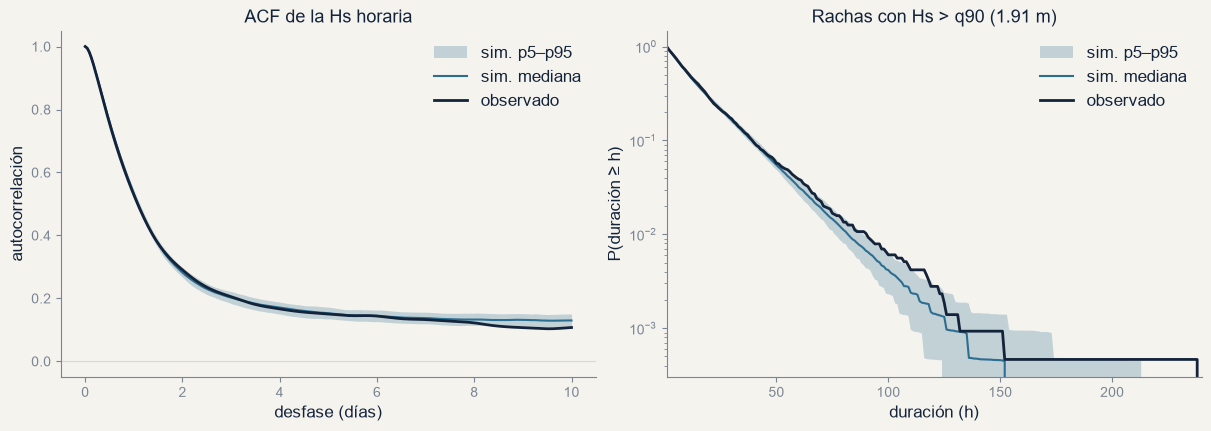

,obs,sim p50,sim p5,sim p95,en banda
métrica,,,,,
ACF 1 día,0.529,0.533,0.521,0.545,True
ACF 3 días,0.205,0.202,0.184,0.222,True
duración media > q90 (h),16.715,16.209,15.706,16.771,True


In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)

#### ACF horaria hasta 10 días
dias = LAGS / 24
banda(axs[0], dias, pila("acf"))
axs[0].plot(dias, est_obs["acf"], color=TINTA, lw=2, label="observado")
axs[0].axhline(0, color="#DDD8CE", lw=0.8)
axs[0].set(xlabel="desfase (días)", ylabel="autocorrelación", title="ACF de la Hs horaria")
axs[0].legend(frameon=False)

#### Duración de las rachas por encima de q90: función de supervivencia
d_max = 240
x = np.arange(1, d_max + 1)
superv = lambda d: np.array([(d >= h).mean() for h in x])
banda(axs[1], x, np.array([superv(e["dur90"]) for e in est_sim]))
axs[1].semilogy(x, superv(est_obs["dur90"]), color=TINTA, lw=2, label="observado")
axs[1].set(xlabel="duración (h)", ylabel="P(duración ≥ h)", title=f"Rachas con Hs > q90 ({U90:.2f} m)", xlim=(1, d_max))
axs[1].set_yscale("log")
axs[1].legend(frameon=False)
fig.savefig(f"figuras/08B_val_persistencia_{GEN}.png", dpi=200)
plt.show()

#### Resumen numérico
dur_med = np.array([e["dur90"].mean() for e in est_sim])
acf24, acf72 = pila("acf")[:, 24], pila("acf")[:, 72]
tabla_persist = pd.DataFrame([
    {"métrica": "ACF 1 día", "obs": est_obs["acf"][24], "sim p50": np.median(acf24), "sim p5": np.percentile(acf24, 5), "sim p95": np.percentile(acf24, 95)},
    {"métrica": "ACF 3 días", "obs": est_obs["acf"][72], "sim p50": np.median(acf72), "sim p5": np.percentile(acf72, 5), "sim p95": np.percentile(acf72, 95)},
    {"métrica": "duración media > q90 (h)", "obs": est_obs["dur90"].mean(), "sim p50": np.median(dur_med), "sim p5": np.percentile(dur_med, 5), "sim p95": np.percentile(dur_med, 95)},
]).set_index("métrica")
tabla_persist["en banda"] = (tabla_persist["sim p5"] <= tabla_persist["obs"]) & (tabla_persist["obs"] <= tabla_persist["sim p95"])
tabla_persist.round(3)

#### 3. Estacionalidad (y ciclo diario, que el PVAR a 6 h no tiene)

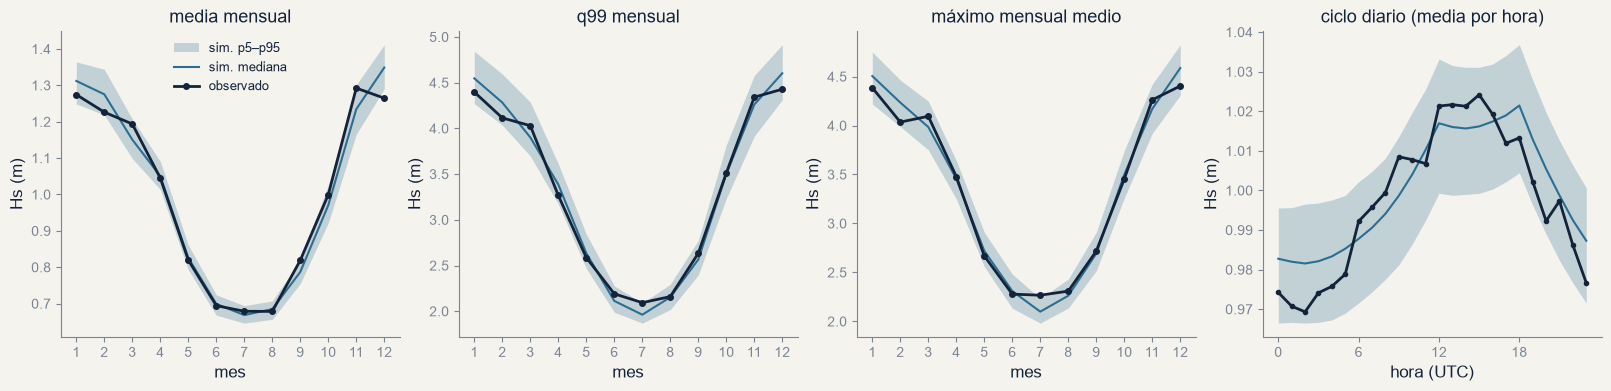

,1,2,3,4,5,6,7,8,9,10,11,12
mes_media,2.9,4.0,-3.6,0.5,0.7,0.7,-1.5,0.9,-3.9,-2.9,-4.5,6.6
mes_q90,-1.2,-0.2,-6.2,-0.8,-0.6,0.7,-3.1,-2.0,-3.8,-3.1,-3.4,5.9
mes_q99,3.4,4.1,-3.2,3.7,1.9,-3.5,-6.3,-0.3,-2.6,-0.3,-1.9,3.9
mes_max,2.7,4.9,-2.7,-0.7,1.9,1.4,-7.4,-2.0,-0.9,1.3,-2.2,4.2


In [10]:
meses = np.arange(1, 13)
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True)
for ax, k, tit in zip(axs[:3], ["mes_media", "mes_q99", "mes_max"],
                      ["media mensual", "q99 mensual", "máximo mensual medio"]):
    banda(ax, meses, pila(k))
    ax.plot(meses, est_obs[k], "o-", color=TINTA, lw=2, ms=4, label="observado")
    ax.set(title=tit, xlabel="mes", ylabel="Hs (m)", xticks=meses)
axs[0].legend(frameon=False, fontsize=9)

horas = np.arange(24)
banda(axs[3], horas, pila("hora_media"))
axs[3].plot(horas, est_obs["hora_media"], "o-", color=TINTA, lw=2, ms=3)
axs[3].set(title="ciclo diario (media por hora)", xlabel="hora (UTC)", ylabel="Hs (m)", xticks=[0, 6, 12, 18])
fig.savefig(f"figuras/08B_val_estacionalidad_{GEN}.png", dpi=200)
plt.show()

#### Sesgo por mes (mediana simulada − observado), en %
pd.DataFrame({k: 100 * (np.median(pila(k), 0) - est_obs[k]) / est_obs[k] for k in ["mes_media", "mes_q90", "mes_q99", "mes_max"]},
             index=meses).round(1).T

#### 4. Variabilidad interanual
Si el emulador solo tuviera variabilidad de alta frecuencia, la dispersión entre años de la media o del q95 anual quedaría por debajo de la observada.

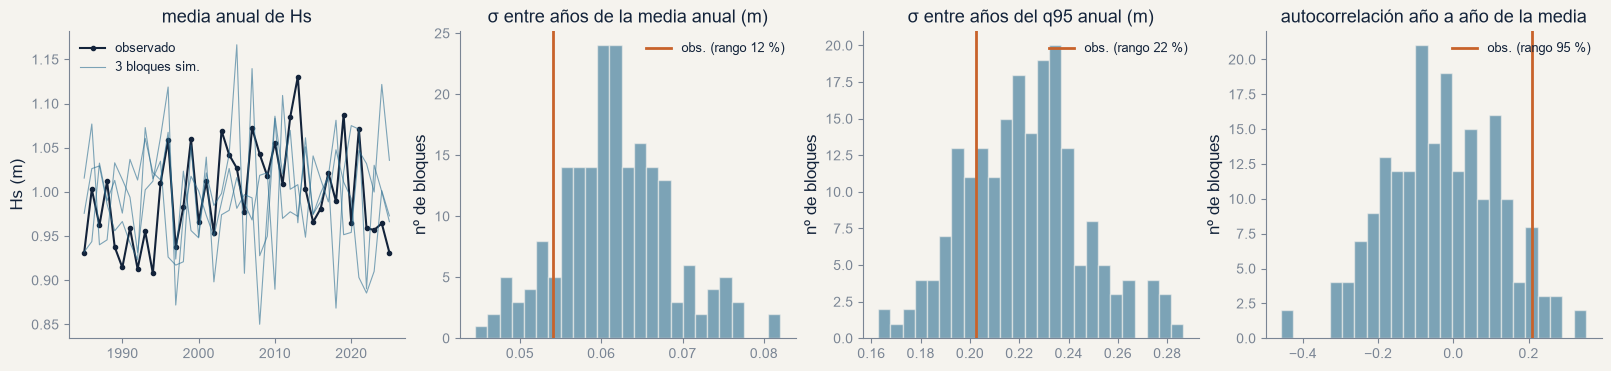

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
σ entre años de la media anual (m),0.054,0.061,0.050,0.075,13.231,True
σ entre años del q95 anual (m),0.203,0.222,0.186,0.264,9.451,True
autocorrelación año a año de la media,0.210,-0.034,-0.255,0.210,-116.271,False


In [11]:
claves = [("std_anual_media", "σ entre años de la media anual (m)"),
          ("std_anual_q95", "σ entre años del q95 anual (m)"),
          ("ac1_anual_media", "autocorrelación año a año de la media")]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6), constrained_layout=True)

#### Serie observada de medias anuales frente a la banda de un bloque simulado cualquiera
anos_obs = np.unique(obs.index.year)
axs[0].plot(anos_obs, est_obs["anual_media"], "o-", color=TINTA, lw=1.5, ms=3, label="observado")
for j in range(3):
    axs[0].plot(anos_obs, est_sim[j]["anual_media"], color=AZUL, lw=0.8, alpha=0.6, label="3 bloques sim." if j == 0 else None)
axs[0].set(title="media anual de Hs", ylabel="Hs (m)")
axs[0].legend(frameon=False, fontsize=9)

for ax, (k, tit) in zip(axs[1:], claves):
    v = pila(k)
    ax.hist(v, bins=25, color=AZUL, alpha=0.6, edgecolor=FONDO)
    ax.axvline(est_obs[k], color=NARANJA, lw=2, label=f"obs. (rango {rango(k):.0f} %)")
    ax.set(title=tit, ylabel="nº de bloques")
    ax.legend(frameon=False, fontsize=9)
fig.savefig(f"figuras/08B_val_interanual_{GEN}.png", dpi=200)
plt.show()

tabla_interanual = pd.DataFrame([fila(t, k) for k, t in claves]).set_index("métrica")
tabla_interanual.round(3)

#### 5. Extremos: máximos anuales, niveles de retorno y temporales

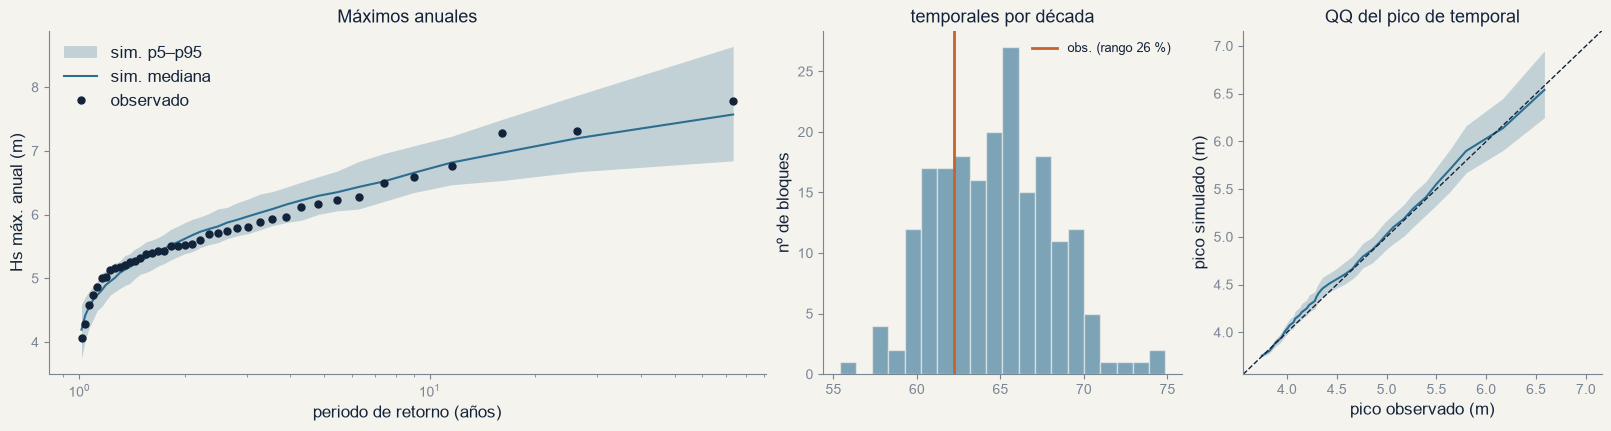

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
xi,-0.132,-0.187,-0.400,0.037,41.128,True
Hs2,5.589,5.607,5.405,5.832,0.331,True
Hs10,6.674,6.705,6.389,6.997,0.465,True
Hs50,7.426,7.398,6.812,7.987,-0.375,True
Hs100,7.698,7.639,6.928,8.510,-0.765,True
temporales / 10 años,62.195,64.756,59.268,69.768,4.118,True


In [12]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2), constrained_layout=True, gridspec_kw={"width_ratios": [2, 1, 1]})

#### Periodo de retorno empírico (Gringorten); misma N en obs. y bloques → misma posición
n = N_ANOS
T_emp = (n + 0.12) / (np.arange(1, n + 1) - 0.44)[::-1]
banda(axs[0], T_emp, pila("am"))
axs[0].plot(T_emp, est_obs["am"], "o", color=TINTA, ms=5, label="observado")
axs[0].set_xscale("log")
axs[0].set(xlabel="periodo de retorno (años)", ylabel="Hs máx. anual (m)", title="Máximos anuales")
axs[0].legend(frameon=False)

#### Temporales por década (picos > q99 separados 72 h)
v = pila("temporales_10a")
axs[1].hist(v, bins=20, color=AZUL, alpha=0.6, edgecolor=FONDO)
axs[1].axvline(est_obs["temporales_10a"], color=NARANJA, lw=2, label=f"obs. (rango {rango('temporales_10a'):.0f} %)")
axs[1].set(title="temporales por década", ylabel="nº de bloques")
axs[1].legend(frameon=False, fontsize=9)

#### Distribución del pico de los temporales (QQ)
qq = np.linspace(0.02, 0.98, 40)
pk_o = np.quantile(est_obs["picos"], qq)
pk_s = np.array([np.quantile(e["picos"], qq) for e in est_sim])
p5, p50, p95 = np.percentile(pk_s, [5, 50, 95], axis=0)
axs[2].fill_between(pk_o, p5, p95, color=AZUL, alpha=0.25, lw=0)
axs[2].plot(pk_o, p50, color=AZUL, lw=1.5)
lim = [pk_o.min() * 0.95, max(pk_o.max(), p95.max()) * 1.03]
axs[2].plot(lim, lim, color=TINTA, ls="--", lw=1)
axs[2].set(xlabel="pico observado (m)", ylabel="pico simulado (m)", title="QQ del pico de temporal", xlim=lim, ylim=lim)
fig.savefig(f"figuras/08B_val_extremos_{GEN}.png", dpi=200)
plt.show()

#### GEV por bloque de 41 años
tabla_extremos = pd.DataFrame([fila(k, k) for k in ["xi"] + [f"Hs{T}" for T in T_RET]] +
                              [fila("temporales / 10 años", "temporales_10a")]).set_index("métrica")
tabla_extremos.round(3)

#### 7. Periodo (Tm02) y dependencia Hs–Tm02
Régimen medio de Tm02 (QQ y media mensual), Tm02 condicionado a Hs (q10/q50/q90 por clase de Hs observada) y dependencia en la cola, χ(u) = P(V > u | U > u) en rangos. En el hindcast del 05B el ruido conjunto dejaba la dependencia algo fuerte y demasiado uniforme (Spearman 0,56 vs 0,51; χ(0,98) 0,47 vs 0,38; registro 27/11).

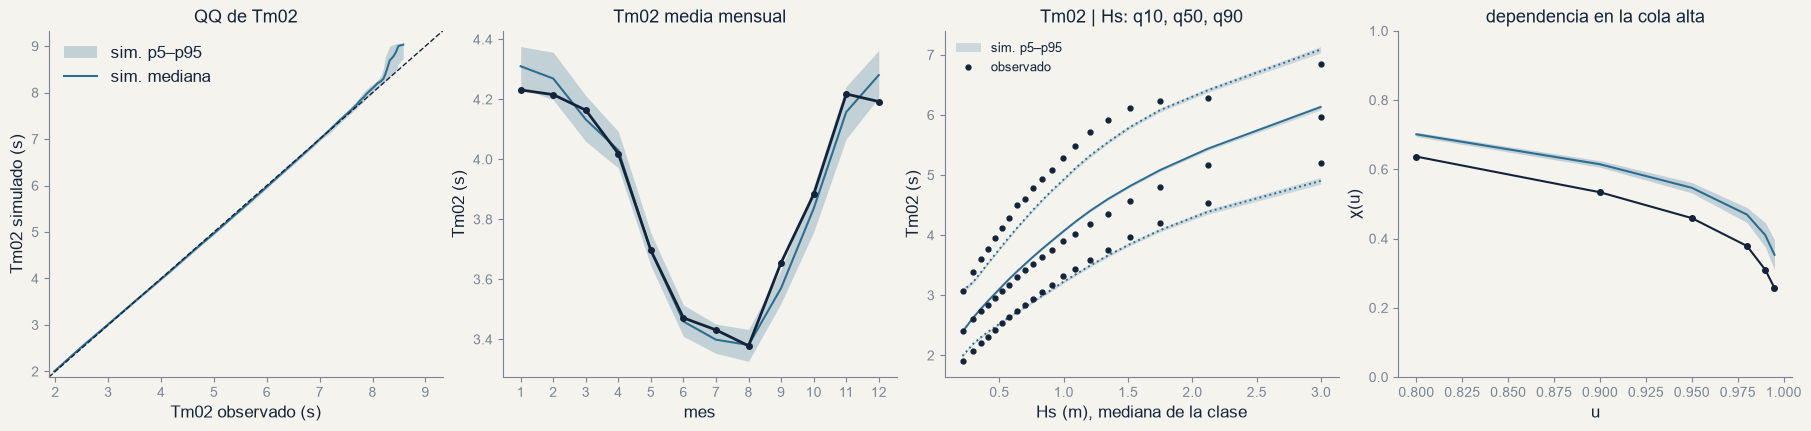

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
Tm02 media (s),3.877,3.876,3.853,3.898,-0.027,True
Tm02 q99 (s),6.875,6.865,6.820,6.905,-0.148,True
Tm02 ACF 1 día,0.442,0.459,0.449,0.470,3.846,False
corr Hs–Tm02,0.772,0.789,0.784,0.793,2.222,False
Spearman Hs–Tm02,0.809,0.816,0.812,0.820,0.951,False
"χ(0,95)",0.459,0.547,0.532,0.562,19.067,False
"χ(0,99)",0.310,0.410,0.376,0.446,32.300,False
"Tm02 en picos de temporal, mediana (s)",6.676,6.711,6.609,6.811,0.527,True
peralte q99,0.071,0.102,0.101,0.103,43.833,False


In [13]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4.2), constrained_layout=True)

#### QQ de Tm02
qs_t = pila("tm_q")
p5, p50, p95 = np.percentile(qs_t, [5, 50, 95], axis=0)
axs[0].fill_between(est_obs["tm_q"], p5, p95, color=AZUL, alpha=0.25, lw=0, label="sim. p5–p95")
axs[0].plot(est_obs["tm_q"], p50, color=AZUL, lw=1.5, label="sim. mediana")
lim = [est_obs["tm_q"].min() * 0.95, max(est_obs["tm_q"].max(), p95.max()) * 1.03]
axs[0].plot(lim, lim, color=TINTA, lw=1, ls="--")
axs[0].set(xlabel="Tm02 observado (s)", ylabel="Tm02 simulado (s)", title="QQ de Tm02", xlim=lim, ylim=lim)
axs[0].legend(frameon=False, loc="upper left")

#### Media mensual
meses = np.arange(1, 13)
banda(axs[1], meses, pila("tm_mes_media"))
axs[1].plot(meses, est_obs["tm_mes_media"], "o-", color=TINTA, lw=2, ms=4, label="observado")
axs[1].set(title="Tm02 media mensual", xlabel="mes", ylabel="Tm02 (s)", xticks=meses)

#### Tm02 | Hs
cond = pila("tm_cond")                                                   # (bloque, clase, q)
for j, ls in enumerate([":", "-", ":"]):
    p5, p50, p95 = np.nanpercentile(cond[:, :, j], [5, 50, 95], axis=0)
    axs[2].fill_between(CENTROS_H, p5, p95, color=AZUL, alpha=0.2, lw=0, label="sim. p5–p95" if j == 1 else None)
    axs[2].plot(CENTROS_H, p50, color=AZUL, lw=1.4, ls=ls)
    axs[2].plot(CENTROS_H, est_obs["tm_cond"][:, j], "o", color=TINTA, ms=3.5, label="observado" if j == 1 else None)
axs[2].set(xlabel="Hs (m), mediana de la clase", ylabel="Tm02 (s)", title="Tm02 | Hs: q10, q50, q90")
axs[2].legend(frameon=False, fontsize=9)

#### χ(u)
banda(axs[3], US, pila("chi"))
axs[3].plot(US, est_obs["chi"], "o-", color=TINTA, lw=1.5, ms=4, label="observado")
axs[3].set(xlabel="u", ylabel="χ(u)", title="dependencia en la cola alta", ylim=(0, 1))
fig.savefig(f"figuras/08B_val_periodo_{GEN}.png", dpi=200)
plt.show()

tabla_periodo = pd.DataFrame([fila(n, k) for n, k in [
    ("Tm02 media (s)", "tm_media"), ("Tm02 q99 (s)", "tm_q99"), ("Tm02 ACF 1 día", "tm_acf24"),
    ("corr Hs–Tm02", "corr_hs_tm"), ("Spearman Hs–Tm02", "spearman_hs_tm"),
    ("χ(0,95)", "chi95"), ("χ(0,99)", "chi99"),
    ("Tm02 en picos de temporal, mediana (s)", "tm_picos_med"),
    ("peralte q99", "peralte_q99"), ("peralte máximo", "peralte_max")]]).set_index("métrica")
tabla_periodo.round(3)

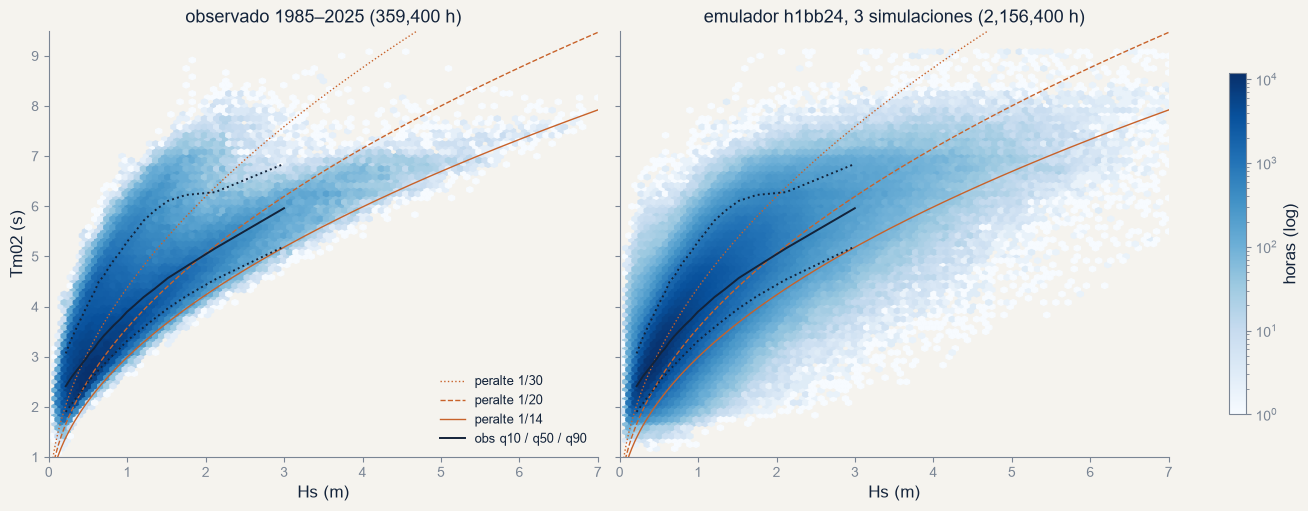

obs       peralte > 1/14: 0.866% | > 0.09: 0.001% | q99 por clase de Hs (0–0.5–1–2–3–∞ m): [0.058 0.066 0.072 0.076 0.077]
emulador  peralte > 1/14: 4.755% | > 0.09: 1.716% | q99 por clase de Hs (0–0.5–1–2–3–∞ m): [0.065 0.097 0.113 0.123 0.142]


In [19]:
#### Scatter Hs–Tm02 (régimen medio): observado vs emulador (3 simulaciones), densidad en escala log
import matplotlib.colors as mcolors
sim = pd.concat([pd.read_parquet(f, columns=["VHM0", "VTM02"]).astype("float64") for f in ficheros[:3]]).dropna()
o = pd.DataFrame({"VHM0": obs, "VTM02": tm_obs}).dropna()
ext = [0, 7, 1, 9.5]
hs_l = np.linspace(0.05, 7, 200)
cond_o = o["VTM02"].groupby(np.digitize(o["VHM0"], BORDES_H)).quantile([0.1, 0.5, 0.9]).unstack()

fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True, sharex=True, sharey=True)
for ax, d, tit in [(axs[0], o, f"observado 1985–2025 ({len(o):,} h)"), (axs[1], sim, f"emulador {GEN}, 3 simulaciones ({len(sim):,} h)")]:
    hb = ax.hexbin(d["VHM0"], d["VTM02"], gridsize=90, extent=ext, bins="log", cmap="Blues", mincnt=1,
                   norm=mcolors.LogNorm(vmin=1e-5, vmax=2e-2) if False else None)
    for s_, ls in [(1 / 30, ":"), (1 / 20, "--"), (1 / 14, "-")]:
        ax.plot(hs_l, np.sqrt(2 * np.pi * hs_l / (9.81 * s_)), color=NARANJA, lw=1, ls=ls, label=f"peralte 1/{round(1 / s_)}")
    for q, ls in [(0.1, ":"), (0.5, "-"), (0.9, ":")]:
        ax.plot(CENTROS_H, cond_o[q].values, color=TINTA, lw=1.4, ls=ls, label="obs q10 / q50 / q90" if q == 0.5 else None)
    ax.set(xlim=ext[:2], ylim=ext[2:], xlabel="Hs (m)", title=tit)
axs[0].set_ylabel("Tm02 (s)")
axs[0].legend(frameon=False, fontsize=9, loc="lower right")
fig.colorbar(hb, ax=axs, shrink=0.8, label="horas (log)")
fig.savefig(f"figuras/08B_scatter_hs_tm02_{GEN}.png", dpi=200)
plt.show()

#### Peralte: dónde se sale el emulador
pe = lambda d: d["VHM0"] / (9.81 * d["VTM02"] ** 2 / (2 * np.pi))
for n, d in [("obs", o), ("emulador", sim)]:
    p = pe(d)
    print(f"{n:9s} peralte > 1/14: {(p > 1 / 14).mean():.3%} | > 0.09: {(p > 0.09).mean():.3%} | "
          f"q99 por clase de Hs (0–0.5–1–2–3–∞ m): {p.groupby(pd.cut(d['VHM0'], [0, 0.5, 1, 2, 3, 20]), observed=True).quantile(0.99).round(3).values}")

#### 6. Resumen

In [14]:
resumen = pd.concat({"régimen medio": tabla_regimen, "persistencia": tabla_persist,
                     "interanual": tabla_interanual, "extremos": tabla_extremos, "periodo": tabla_periodo})
hs_ = resumen.drop(index="periodo", level=0)
print(f"Hs: {hs_['en banda'].sum()} de {len(hs_)} métricas dentro de la banda p5–p95 (en el 08 con el ruido de Hs sola: 18 de 18)")
print(f"periodo: {tabla_periodo['en banda'].sum()} de {len(tabla_periodo)}")
resumen.round(3)

Hs: 17 de 18 métricas dentro de la banda p5–p95 (en el 08 con el ruido de Hs sola: 18 de 18)
periodo: 3 de 10


obs  sim p50  sim p5  \
              métrica                                                           
régimen medio media                                    0.998    1.000   0.984   
              std                                      0.731    0.727   0.709   
              q50                                      0.796    0.801   0.788   
              q90                                      1.905    1.883   1.854   
              q99                                      3.731    3.762   3.657   
              q99.9                                    5.304    5.380   5.186   
persistencia  ACF 1 día                                0.529    0.533   0.521   
              ACF 3 días                               0.205    0.202   0.184   
              duración media > q90 (h)                16.715   16.209  15.706   
interanual    σ entre años de la media anual (m)       0.054    0.061   0.050   
              σ entre años del q95 anual (m)           0.203    0.222   0.186   
              autocorrelación año a año de la media    0.210   -0.034  -0.255   
extremos      xi                                      -0.132   -0.187  -0.400   
              Hs2                                      5.589    5.607   5.405   
              Hs10                                     6.674    6.705   6.389   
              Hs50                                     7.426    7.398   6.812   
              Hs100                                    7.698    7.639   6.928   
              temporales / 10 años                    62.195   64.756  59.268   
periodo       Tm02 media (s)                           3.877    3.876   3.853   
              Tm02 q99 (s)                             6.875    6.865   6.820   
              Tm02 ACF 1 día                           0.442    0.459   0.449   
              corr Hs–Tm02                             0.772    0.789   0.784   
              Spearman Hs–Tm02                         0.809    0.816   0.812   
              χ(0,95)                                  0.459    0.547   0.532   
              χ(0,99)                                  0.310    0.410   0.376   
              Tm02 en picos de temporal, mediana (s)   6.676    6.711   6.609   
              peralte q99                              0.071    0.102   0.101   
              peralte máximo                           0.096    0.396   0.338   

                                                      sim p95  sesgo %  \
              métrica                                                    
régimen medio media                                     1.015    0.252   
              std                                       0.741   -0.593   
              q50                                       0.815    0.623   
              q90                                       1.914   -1.141   
              q99                                       3.846    0.828   
              q99.9                                     5.567    1.435   
persistencia  ACF 1 día                                 0.545      NaN   
              ACF 3 días                                0.222      NaN   
              duración media > q90 (h)                 16.771      NaN   
interanual    σ entre años de la media anual (m)        0.075   13.231   
              σ entre años del q95 anual (m)            0.264    9.451   
              autocorrelación año a año de la media     0.210 -116.271   
extremos      xi                                        0.037   41.128   
              Hs2                                       5.832    0.331   
              Hs10                                      6.997    0.465   
              Hs50                                      7.987   -0.375   
              Hs100                                     8.510   -0.765   
              temporales / 10 años                     69.768    4.118   
periodo       Tm02 media (s)                            3.898   -0.027   
              Tm02 q99 (s)                              6.905   -0.148  

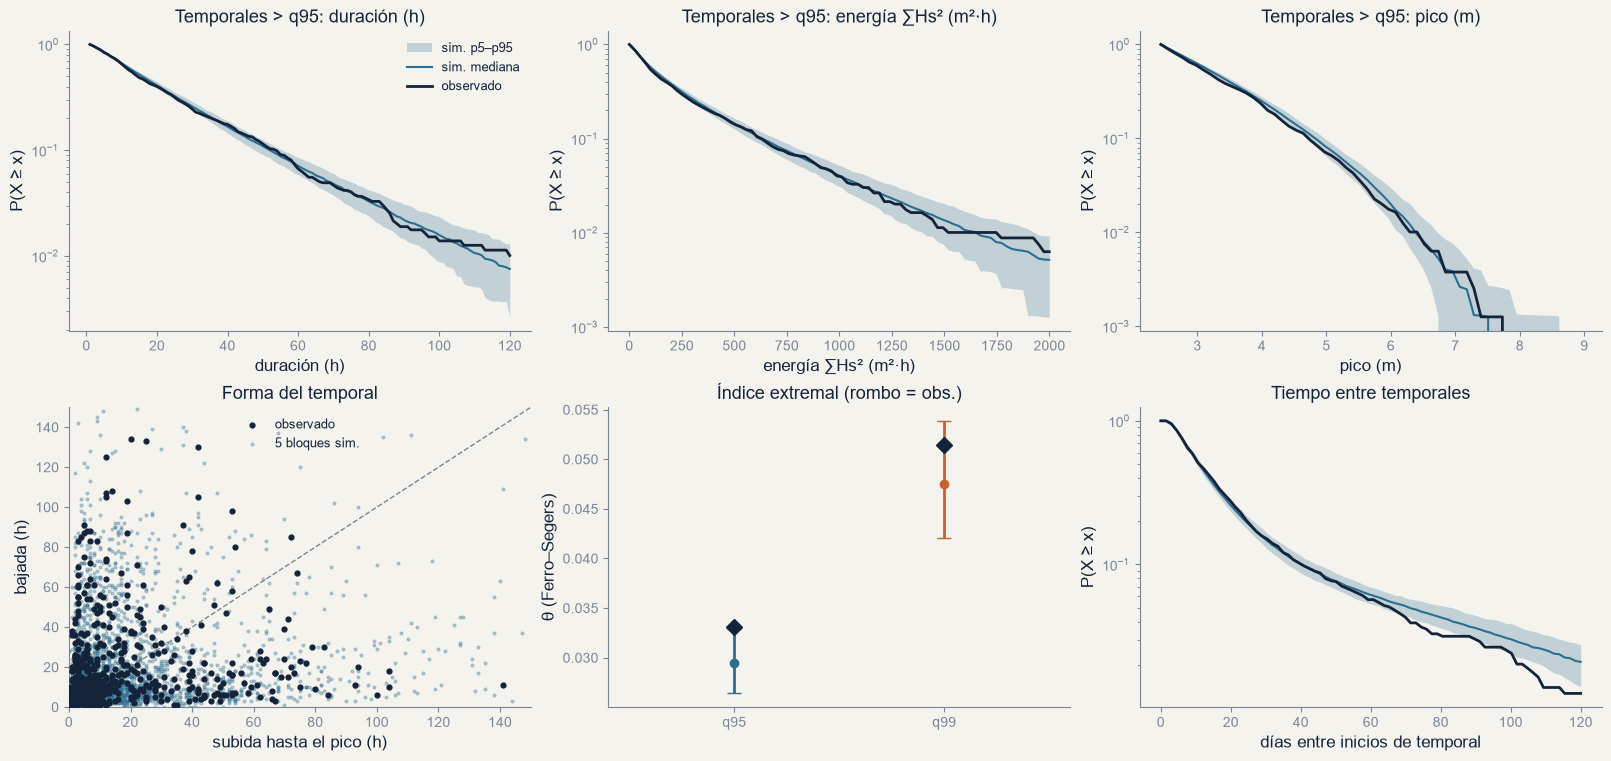

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
temporales > q95 / año,19.317,18.634,17.923,19.563,-3.535,True
dispersión nº/año (var/media),0.370,0.627,0.427,0.915,69.617,False
duración media (h),22.662,22.705,21.487,24.061,0.192,True
duración q90 (h),53.000,51.200,47.000,55.000,-3.396,True
energía media,246.827,253.642,236.567,271.663,2.761,True
subida / bajada (mediana),0.667,0.857,0.750,1.000,28.571,False
θ q95,0.033,0.029,0.026,0.033,-10.999,False
θ q99,0.051,0.047,0.042,0.054,-7.644,True
temporales > q99 / año,6.293,6.488,5.951,6.978,3.101,True


In [15]:
#### 5B. Temporales: duración, energía, forma, agrupamiento y cronología (umbral q95)
def figura_5b(est_list, nombre):
    """Figura y tabla de la sección 5B para una lista de estadísticos por bloque (emulador o hindcast)."""
    ev_o = est_obs["ev95"]
    ev_s = [e["ev95"] for e in est_list]
    superv = lambda x, grid: np.array([(x >= g).mean() for g in grid])

    fig, axs = plt.subplots(2, 3, figsize=(16, 7.5), constrained_layout=True)
    for ax, col, tit, grid in [(axs[0, 0], "dur", "duración (h)", np.arange(1, 121)),
                               (axs[0, 1], "energia", "energía ∑Hs² (m²·h)", np.linspace(0, ev_o["energia"].quantile(.99) * 1.3, 80)),
                               (axs[0, 2], "pico", "pico (m)", np.linspace(U95, ev_o["pico"].max() * 1.15, 60))]:
        banda(ax, grid, np.array([superv(d[col].values, grid) for d in ev_s]))
        ax.semilogy(grid, superv(ev_o[col].values, grid), color=TINTA, lw=2, label="observado")
        ax.set(title=f"Temporales > q95: {tit}", xlabel=tit, ylabel="P(X ≥ x)")
    axs[0, 0].legend(frameon=False, fontsize=9)

    #### Forma: subida frente a bajada
    axs[1, 0].scatter(ev_o["subida"], ev_o["bajada"], s=12, color=TINTA, label="observado", zorder=3)
    d0 = pd.concat(ev_s[:5])
    axs[1, 0].scatter(d0["subida"], d0["bajada"], s=4, color=AZUL, alpha=0.3, label="5 bloques sim.")
    axs[1, 0].plot([0, 150], [0, 150], color=GRIS, ls="--", lw=1)
    axs[1, 0].set(xlim=(0, 150), ylim=(0, 150), xlabel="subida hasta el pico (h)", ylabel="bajada (h)", title="Forma del temporal")
    axs[1, 0].legend(frameon=False, fontsize=9)

    #### Índice extremal
    for j, (q, c) in enumerate([(95, AZUL), (99, NARANJA)]):
        v = np.array([e[f"theta_q{q}"] for e in est_list]); p5, p50, p95 = np.percentile(v, [5, 50, 95])
        axs[1, 1].errorbar(j, p50, yerr=[[p50 - p5], [p95 - p50]], fmt="o", color=c, capsize=5, lw=2)
        axs[1, 1].plot(j, est_obs[f"theta_q{q}"], "D", color=TINTA, ms=8)
    axs[1, 1].set(xticks=[0, 1], xticklabels=["q95", "q99"], xlim=(-0.6, 1.6), ylabel="θ (Ferro–Segers)",
                  title="Índice extremal (rombo = obs.)")

    #### Tiempo entre temporales
    ia = lambda d: np.diff(d["inicio"].values) / 24
    grid = np.linspace(0, 120, 80)
    banda(axs[1, 2], grid, np.array([superv(ia(d), grid) for d in ev_s]))
    axs[1, 2].semilogy(grid, superv(ia(ev_o), grid), color=TINTA, lw=2)
    axs[1, 2].set(xlabel="días entre inicios de temporal", ylabel="P(X ≥ x)", title="Tiempo entre temporales")
    fig.savefig(f"figuras/08B_val_temporales_{nombre}.png", dpi=200)
    plt.show()

    #### Tabla
    def fila_ev(nombre, f_obs, f_sim):
        s = np.array([f_sim(e) for e in est_list]); o = f_obs(est_obs)
        a, m, b = np.percentile(s, [5, 50, 95])
        return {"métrica": nombre, "obs": o, "sim p50": m, "sim p5": a, "sim p95": b,
                "sesgo %": 100 * (m - o) / o if o else np.nan, "en banda": a <= o <= b}
    tabla_temp = pd.DataFrame([
        fila_ev("temporales > q95 / año",   lambda e: len(e["ev95"]) / N_ANOS, lambda e: len(e["ev95"]) / N_ANOS),
        fila_ev("dispersión nº/año (var/media)", lambda e: e["n_ev95_ano"].var() / e["n_ev95_ano"].mean(),
                                                 lambda e: e["n_ev95_ano"].var() / e["n_ev95_ano"].mean()),
        fila_ev("duración media (h)",        lambda e: e["ev95"]["dur"].mean(), lambda e: e["ev95"]["dur"].mean()),
        fila_ev("duración q90 (h)",          lambda e: e["ev95"]["dur"].quantile(.9), lambda e: e["ev95"]["dur"].quantile(.9)),
        fila_ev("energía media",             lambda e: e["ev95"]["energia"].mean(), lambda e: e["ev95"]["energia"].mean()),
        fila_ev("subida / bajada (mediana)", lambda e: (e["ev95"]["subida"] / e["ev95"]["bajada"].clip(lower=1)).median(),
                                             lambda e: (e["ev95"]["subida"] / e["ev95"]["bajada"].clip(lower=1)).median()),
        fila_ev("θ q95", lambda e: e["theta_q95"], lambda e: e["theta_q95"]),
        fila_ev("θ q99", lambda e: e["theta_q99"], lambda e: e["theta_q99"]),
        fila_ev("temporales > q99 / año",   lambda e: len(e["ev99"]) / N_ANOS, lambda e: len(e["ev99"]) / N_ANOS),
    ]).set_index("métrica")
    return tabla_temp

figura_5b(est_sim, GEN).round(3)

50 realizaciones del hindcast (05B)


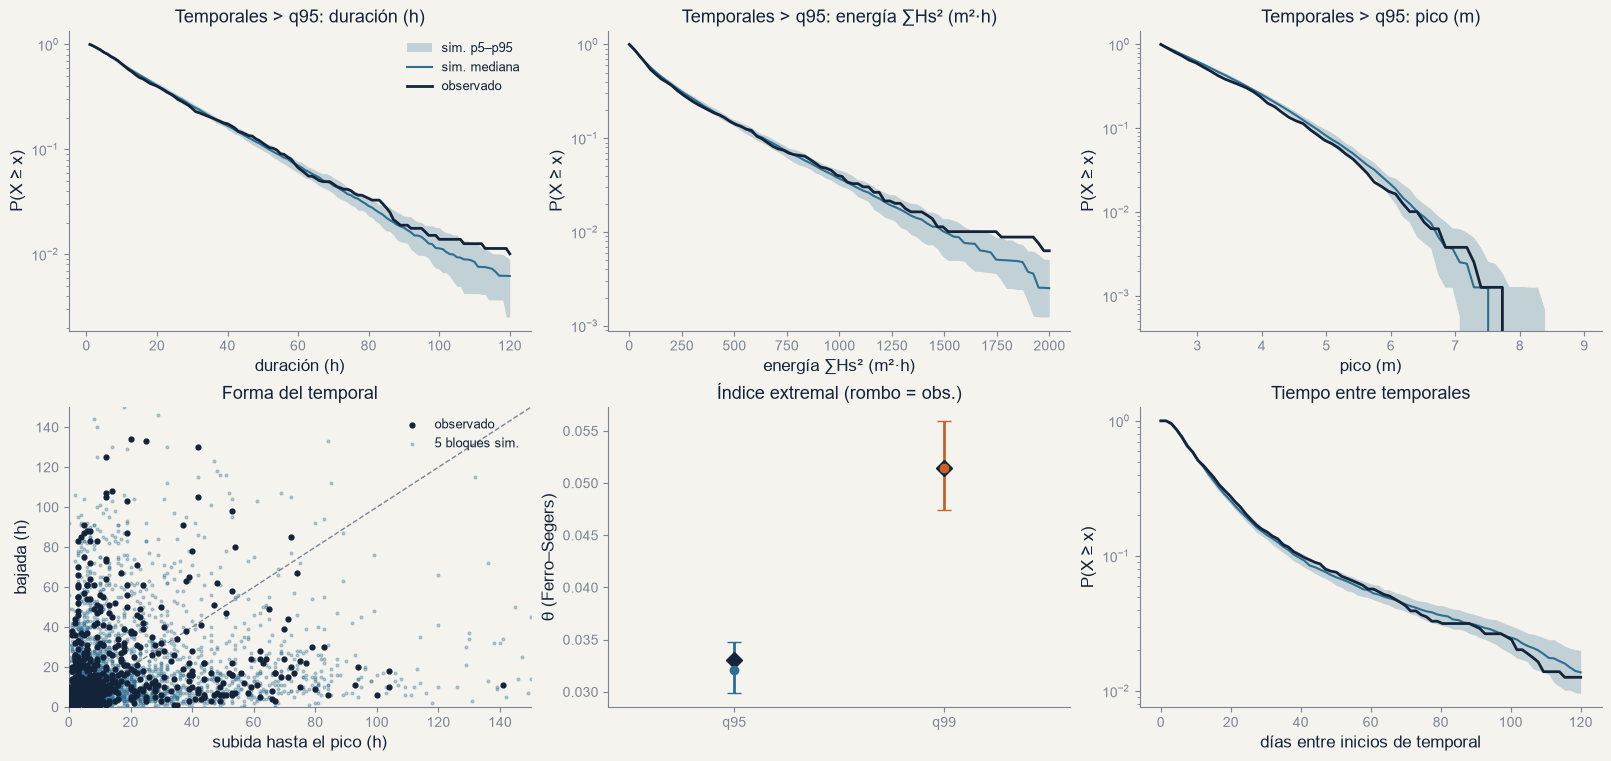

,obs,sim p50,sim p5,sim p95,sesgo %,en banda
métrica,,,,,,
temporales > q95 / año,19.317,19.500,19.073,20.317,0.947,True
dispersión nº/año (var/media),0.370,0.573,0.443,0.808,54.987,False
duración media (h),22.662,22.396,21.653,23.057,-1.172,True
duración q90 (h),53.000,51.000,48.890,53.385,-3.774,True
energía media,246.827,248.082,238.153,254.870,0.509,True
subida / bajada (mediana),0.667,0.857,0.750,1.000,28.571,False
θ q95,0.033,0.032,0.030,0.035,-2.994,True
θ q99,0.051,0.051,0.047,0.056,0.032,True
temporales > q99 / año,6.293,6.768,6.266,7.154,7.558,True


In [16]:
#### Misma validación con el hindcast del 05B (f histórica + ruido conjunto, sin PVAR): ¿qué parte es del generador?
olas_h = pd.read_pickle(f"outputs/ruido/olas_hindcast_{point}.pkl")      # columnas (variable, realización)
series_07 = [olas_h["VHM0"][c] for c in olas_h["VHM0"].columns]         # Hs, para las celdas siguientes
series_07_tm = [olas_h["VTM02"][c] for c in olas_h["VTM02"].columns]

est_07 = []
for s, t in zip(series_07, series_07_tm):
    s = s.astype("float64").loc["1985":"2025"]
    s = s[s.index.year.isin(np.unique(obs.index.year))]       # mismos años que la observación
    est_07.append(estadisticos(s, t.astype("float64")))
print(f"{len(est_07)} realizaciones del hindcast (05B)")

est_sim_08 = est_sim                                          # alias para las celdas siguientes (emulador)
figura_5b(est_07, "hindcast_hstm").round(3)

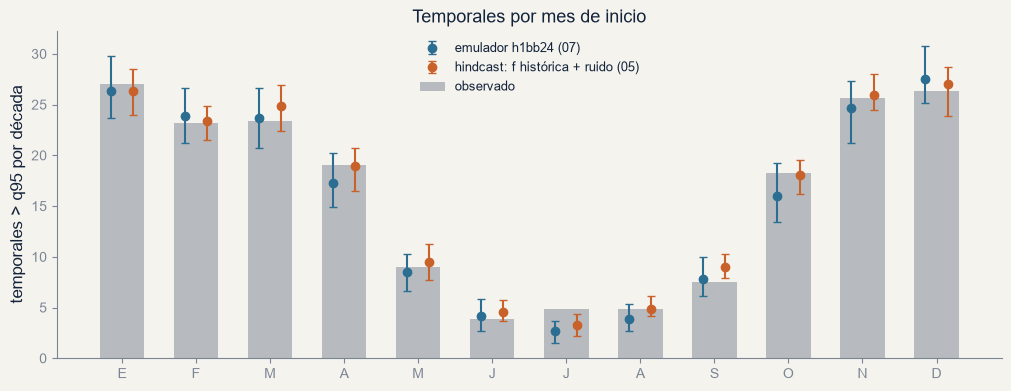

                       1     2     3     4    5    6    7    8    9     10  \
obs                  27.1  23.2  23.4  19.0  9.0  3.9  4.9  4.9  7.6  18.3   
emulador h1bb24 p50  26.3  23.9  23.7  17.3  8.5  4.1  2.7  3.9  7.8  16.0   
hindcast p50         26.3  23.4  24.9  18.9  9.5  4.5  3.3  4.9  9.0  18.0   

                       11    12  
obs                  25.6  26.3  
emulador h1bb24 p50  24.6  27.6  
hindcast p50         26.0  27.1  


In [17]:
#### Temporales > q95 por mes (por década): ¿faltan en primavera/otoño?
def por_mes(e, s_index):
    """Nº de temporales > q95 por mes de inicio, por década."""
    ini = e["ev95"]["inicio"].astype(int).values
    n_anos = len(np.unique(s_index.year))
    return np.bincount(s_index[ini].month, minlength=13)[1:] * 10 / n_anos

mo = por_mes(est_obs, obs.asfreq("h").index)
#### índices horarios de cada bloque / simulación para traducir 'inicio' a fecha
def indices_08():
    out = []
    for fic in ficheros:
        hs = pd.read_parquet(fic, columns=["VHM0"])["VHM0"]
        anos = np.unique(hs.index.year); anos = anos[[hs.loc[str(a)].size >= 8700 for a in anos]]
        for b in range(len(anos) // N_ANOS):
            out.append(hs[hs.index.year.isin(anos[b * N_ANOS:(b + 1) * N_ANOS])].asfreq("h").index)
    return out
idx_08 = indices_08()
m08 = np.array([por_mes(e, ix) for e, ix in zip(est_sim_08, idx_08)])
m07 = np.array([por_mes(e, s.loc["1985":"2025"].asfreq("h").index) for e, s in zip(est_07, series_07)])

meses = np.arange(1, 13)
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
for arr_, c, lab, dx in [(m08, AZUL, f"emulador {GEN} (07)", -0.15), (m07, NARANJA, "hindcast: f histórica + ruido (05)", 0.15)]:
    p5, p50, p95 = np.percentile(arr_, [5, 50, 95], axis=0)
    ax.errorbar(meses + dx, p50, yerr=[p50 - p5, p95 - p50], fmt="o", color=c, capsize=3, lw=1.5, label=lab)
ax.bar(meses, mo, width=0.6, color=GRIS, alpha=0.5, label="observado")
ax.set(xticks=meses, xticklabels=["E","F","M","A","M","J","J","A","S","O","N","D"],
       ylabel="temporales > q95 por década", title="Temporales por mes de inicio")
ax.legend(frameon=False, fontsize=9)
fig.savefig(f"figuras/08B_val_temporales_mes_{GEN}.png", dpi=200)
plt.show()

print(pd.DataFrame({"obs": mo, f"emulador {GEN} p50": np.median(m08, 0), "hindcast p50": np.median(m07, 0)},
                   index=meses).round(1).T)

In [18]:
#### ¿Faltan horas por encima de q95 o faltan episodios? (por mes, por década)
def horas_mes(s_values, s_index, u):
    n_anos = len(np.unique(s_index.year))
    return np.bincount(s_index[s_values > u].month, minlength=13)[1:] * 10 / n_anos

obs_h = obs.asfreq("h")
h_obs = horas_mes(obs_h.values, obs_h.index, U95)
h_07 = np.array([horas_mes(s.loc["1985":"2025"].values, s.loc["1985":"2025"].index, U95) for s in series_07])

tabla = pd.DataFrame({
    "horas obs": h_obs, "horas hindcast": np.median(h_07, 0),
    "episodios obs": mo, "episodios hindcast": np.median(m07, 0)}, index=meses)
tabla["h/episodio obs"] = tabla["horas obs"] / tabla["episodios obs"]
tabla["h/episodio hindcast"] = tabla["horas hindcast"] / tabla["episodios hindcast"]
tabla.round(1).T

,1,2,3,4,5,6,7,8,9,10,11,12
horas obs,766.3,618.0,622.7,301.2,112.2,43.4,29.0,32.7,106.1,335.9,682.9,727.1
horas hindcast,727.7,604.1,608.8,323.2,124.4,39.3,22.2,45.2,102.1,344.9,684.5,739.9
episodios obs,27.1,23.2,23.4,19.0,9.0,3.9,4.9,4.9,7.6,18.3,25.6,26.3
episodios hindcast,26.3,23.4,24.9,18.9,9.5,4.5,3.3,4.9,9.0,18.0,26.0,27.1
h/episodio obs,28.3,26.7,26.6,15.8,12.4,11.1,6.0,6.7,14.0,18.4,26.7,27.6
h/episodio hindcast,27.6,25.8,24.5,17.1,13.1,8.7,6.7,9.3,11.3,19.1,26.4,27.3
